In [ ]:
!pip install geopandas shapely pandas numpy matplotlib


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence"

ROAD_PATH = os.path.join(
    PROJECT_PATH, "datasets/raw/roads"
)

OUTPUT_PATH = os.path.join(
    PROJECT_PATH, "datasets/processed"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

print("Project directory ready!")

Project directory ready!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

# Check the contents of MyDrive
drive_path = "/content/drive/MyDrive"

print("Folders and files in MyDrive:")
for item in os.listdir(drive_path):
    print(item)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folders and files in MyDrive:
Colab Notebooks
Smart_Ride_Intelligence 


In [ ]:
import os

search_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_path):
    for file in files:
        if file.endswith(".geojson"):
            print(os.path.join(root, file))

/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/poi.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/state_highways.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/national_highways.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/major_roads.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/traffic50.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/link_roads.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/traffic_junctions.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/parking_southeast.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/flyovers.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/parking_southwest.geojson
/content/drive/MyDrive/Smart_Ride_Intelligence /datasets/raw/roads/parking_north.geojson


In [ ]:
import geopandas as gpd
import os

road_files = [
    "major_roads.geojson",
    "link_roads.geojson",
    "national_highways.geojson",
    "state_highways.geojson",
    "flyovers.geojson"
]

road_frames = []

for filename in road_files:

    filepath = os.path.join(ROAD_PATH, filename)

    gdf = gpd.read_file(filepath)

    print(
        filename,
        "Features:", len(gdf),
        "Geometry:", gdf.geom_type.unique()
    )

    road_frames.append(gdf)

roads = gpd.GeoDataFrame(
    pd.concat(road_frames, ignore_index=True),
    crs=road_frames[0].crs
)

print("Total road features:", len(roads))

major_roads.geojson Features: 1000 Geometry: ['LineString']
link_roads.geojson Features: 1000 Geometry: ['LineString']
national_highways.geojson Features: 456 Geometry: ['LineString']
state_highways.geojson Features: 76 Geometry: ['LineString']
flyovers.geojson Features: 42 Geometry: ['LineString']
Total road features: 2574


In [ ]:
import random
from shapely.geometry import LineString, MultiLineString

# Check coordinate reference system
print("Original CRS:", roads.crs)

# GeoJSON road coordinates are generally WGS84.
# If CRS is missing, verify the coordinates are longitude/latitude
# before assigning EPSG:4326.
if roads.crs is None:
    raise ValueError("Road CRS is missing. Verify and set it first.")

# Convert to metric CRS
roads_m = roads.to_crs("EPSG:32645")

# Extract line geometries
road_segments = []

for _, row in roads_m.iterrows():

    geom = row.geometry

    if geom is None or geom.is_empty:
        continue

    if geom.geom_type == "LineString":
        lines = [geom]

    elif geom.geom_type == "MultiLineString":
        lines = list(geom.geoms)

    else:
        continue

    for line in lines:

        if line.length < 20:
            continue

        road_name = None

        for col in ["name", "road_name", "Name", "NAME"]:
            if col in roads_m.columns:
                value = row.get(col)

                if value is not None and str(value).strip():
                    road_name = str(value)
                    break

        road_segments.append({
            "geometry": line,
            "road_name": road_name
        })

print("Usable road segments:", len(road_segments))

Original CRS: EPSG:4326
Usable road segments: 2270


In [ ]:
import numpy as np
import geopandas as gpd

def generate_road_location():

    segment = random.choice(road_segments)

    line = segment["geometry"]

    distance = random.uniform(0, line.length)

    point = line.interpolate(distance)

    # Convert projected coordinates back to WGS84
    point_4326 = gpd.GeoSeries(
        [point],
        crs="EPSG:32645"
    ).to_crs("EPSG:4326").iloc[0]

    road_name = segment["road_name"]

    if not road_name:
        road_name = "Bhubaneswar road segment"

    return {
        "location_name": road_name,
        "latitude": point_4326.y,
        "longitude": point_4326.x
    }

In [ ]:
for i in range(5):
    print(generate_road_location())

{'location_name': 'Bhubaneswar road segment', 'latitude': 20.156530797280762, 'longitude': 85.71420647046388}
{'location_name': 'Bhubaneswar road segment', 'latitude': 20.27564044621532, 'longitude': 85.81748159220572}
{'location_name': 'Bhubaneswar road segment', 'latitude': 20.163084888229907, 'longitude': 85.71064692032245}
{'location_name': 'Bhubaneswar road segment', 'latitude': 20.161070504853395, 'longitude': 85.70556592891938}
{'location_name': 'Bhubaneswar road segment', 'latitude': 20.154534075319823, 'longitude': 85.60171354228194}


FORUM DATASET



In [ ]:
templates = {

    "Traffic": [
        (
            "Heavy traffic near {location}",
            "Vehicles are moving very slowly near {location}, causing congestion."
        ),
        (
            "Traffic congestion reported",
            "A long queue of vehicles has formed near {location}."
        ),
        (
            "Slow-moving traffic",
            "Traffic movement is slow near {location}, especially during peak hours."
        ),
        (
            "Traffic buildup near road junction",
            "Vehicles are experiencing delays while crossing {location}."
        ),
        (
            "Congestion during evening hours",
            "Traffic density appears high near {location} during the evening."
        )
    ],

    "Road Hazard": [
        (
            "Potholes reported near {location}",
            "Several potholes are present on the road near {location}."
        ),
        (
            "Damaged road surface",
            "The road surface near {location} is uneven and contains damaged patches."
        ),
        (
            "Debris on the road",
            "Loose construction debris is present along the road near {location}."
        ),
        (
            "Uneven road conditions",
            "Drivers may experience difficulty due to uneven road conditions near {location}."
        ),
        (
            "Road obstruction",
            "An obstruction has been reported on the road near {location}."
        )
    ],

    "Accident": [
        (
            "Vehicle collision reported",
            "A vehicle collision is reported in the vicinity of {location}."
        ),
        (
            "Minor accident near road junction",
            "A simulated minor accident report is associated with {location}."
        ),
        (
            "Accident-related traffic delay",
            "Traffic movement may be affected by an accident report near {location}."
        ),
        (
            "Road incident reported",
            "A road incident has been reported near {location}."
        )
    ],

    "Construction": [
        (
            "Road construction near {location}",
            "Construction work is reported along the road near {location}."
        ),
        (
            "Road repair work ongoing",
            "Maintenance and repair activities are taking place near {location}."
        ),
        (
            "Temporary road diversion",
            "A temporary traffic diversion is associated with roadwork near {location}."
        ),
        (
            "Lane restrictions due to construction",
            "Some road lanes are assumed to be unavailable due to construction near {location}."
        )
    ],

    "Waterlogging": [
        (
            "Waterlogging near {location}",
            "Water has accumulated on the road near {location}."
        ),
        (
            "Rainwater accumulation",
            "Rainwater accumulation is reported along the road near {location}."
        ),
        (
            "Flooded road section",
            "A section of the road near {location} is described as waterlogged."
        ),
        (
            "Heavy rainfall and water accumulation",
            "Water accumulation following heavy rainfall is reported near {location}."
        )
    ],

    "Safety Concern": [
        (
            "Poor street lighting",
            "Street lighting is described as inadequate near {location}."
        ),
        (
            "Poor visibility at night",
            "Visibility may be reduced near {location} during nighttime."
        ),
        (
            "Unsafe road conditions",
            "The road section near {location} has been described as potentially unsafe."
        ),
        (
            "Limited pedestrian visibility",
            "Pedestrian visibility is described as poor near {location}."
        )
    ],

    "Route Tip": [
        (
            "Alternative route suggestion",
            "An alternative road near {location} may be worth considering."
        ),
        (
            "Suggested route for riders",
            "Riders may consider exploring another connecting road near {location}."
        ),
        (
            "Travel suggestion",
            "Consider checking alternative roads before travelling through {location}."
        ),
        (
            "Route information",
            "A connecting road near {location} may provide another travel option."
        )
    ],

    "Normal": [
        (
            "Road conditions appear normal",
            "The road near {location} is described as clear with normal movement."
        ),
        (
            "Smooth traffic movement",
            "Vehicles are reportedly moving smoothly near {location}."
        ),
        (
            "Clear road conditions",
            "No traffic-related issue is mentioned for the road near {location}."
        ),
        (
            "Normal travel conditions",
            "Travel conditions are described as normal near {location}."
        )
    ]
}

In [ ]:
from datetime import timedelta
import pandas as pd
import random
import uuid

random.seed(42)
np.random.seed(42)

categories = list(templates.keys())

severity_options = {
    "Traffic": ["Low", "Medium", "High"],
    "Road Hazard": ["Medium", "High"],
    "Accident": ["Medium", "High"],
    "Construction": ["Low", "Medium"],
    "Waterlogging": ["Medium", "High"],
    "Safety Concern": ["Low", "Medium", "High"],
    "Route Tip": ["Low"],
    "Normal": ["Low"]
}

severity_weights = {
    "Traffic": [0.2, 0.5, 0.3],
    "Road Hazard": [0.4, 0.6],
    "Accident": [0.4, 0.6],
    "Construction": [0.6, 0.4],
    "Waterlogging": [0.5, 0.5],
    "Safety Concern": [0.4, 0.4, 0.2],
    "Route Tip": [1.0],
    "Normal": [1.0]
}

expiry_hours = {
    "Traffic": 4,
    "Road Hazard": 720,
    "Accident": 6,
    "Construction": 168,
    "Waterlogging": 12,
    "Safety Concern": 168,
    "Route Tip": 168,
    "Normal": 4
}

sentiments = {
    "Traffic": "Negative",
    "Road Hazard": "Negative",
    "Accident": "Negative",
    "Construction": "Neutral",
    "Waterlogging": "Negative",
    "Safety Concern": "Negative",
    "Route Tip": "Positive",
    "Normal": "Positive"
}

In [ ]:
import pandas as pd
import random
import numpy as np

NUM_POSTS = 1000

now = pd.Timestamp.now(tz="Asia/Kolkata")

posts = []

for i in range(NUM_POSTS):

    post_id = f"P{i+1:05d}"

    # Select category
    category = random.choice(categories)

    # Select text template
    template_index = random.randrange(
        len(templates[category])
    )

    title_template, text_template = templates[category][template_index]

    # Generate geographical location
    loc = generate_road_location()

    location = loc["location_name"]

    title = title_template.format(location=location)
    text = text_template.format(location=location)

    # Generate severity
    severity = random.choices(
        severity_options[category],
        weights=severity_weights[category]
    )[0]

    # Generate timestamps
    created_at = now - pd.Timedelta(
        hours=random.uniform(3, 720)
    )

    observed_at = created_at - pd.Timedelta(
        minutes=random.randint(0, 180)
    )

    expires_at = (
        created_at +
        pd.Timedelta(hours=expiry_hours[category])
    )

    status = (
        "Active" if expires_at > now
        else "Expired"
    )

    post = {
        "post_id": post_id,
        "user_id": f"U{random.randint(1, 100):03d}",
        "title": title,
        "text": text,
        "category": category,
        "subcategory": template_index,
        "severity": severity,
        "location_name": location,
        "latitude": loc["latitude"],
        "longitude": loc["longitude"],
        "created_at": created_at.isoformat(),
        "observed_at": observed_at.isoformat(),
        "expires_at": expires_at.isoformat(),
        "sentiment": sentiments[category],
        "upvotes": random.randint(0, 50),
        "comment_count": 0,
        "status": status,
        "source_type": "synthetic",
        "verification_status": "synthetic_unverified",
        "is_synthetic": True,
        "template_id": f"{category}_{template_index+1:02d}"
    }

    posts.append(post)

forum_posts = pd.DataFrame(posts)

print("Total posts:", len(forum_posts))
print(forum_posts.head())

Total posts: 1000
  post_id user_id                                            title  \
0  P00001    U012  Potholes reported near Bhubaneswar road segment   
1  P00002    U026                     Alternative route suggestion   
2  P00003    U090                       Suggested route for riders   
3  P00004    U013                           Unsafe road conditions   
4  P00005    U011                           Unsafe road conditions   

                                                text        category  \
0  Several potholes are present on the road near ...     Road Hazard   
1  An alternative road near Bhubaneswar road segm...       Route Tip   
2  Riders may consider exploring another connecti...       Route Tip   
3  The road section near Bhubaneswar road segment...  Safety Concern   
4  The road section near Bhubaneswar road segment...  Safety Concern   

   subcategory severity             location_name   latitude  longitude  ...  \
0            0   Medium  Bhubaneswar road segmen

In [ ]:
comment_templates = {

    "Traffic": [
        "Traffic conditions are described as slow in this scenario.",
        "An alternative route may be worth checking.",
        "This report may be useful to other riders.",
        "Consider checking the route before travelling."
    ],

    "Road Hazard": [
        "The road condition should be checked carefully.",
        "This may require attention from the concerned authorities.",
        "Riders should remain cautious in this scenario.",
        "An alternative connecting road may be considered."
    ],

    "Accident": [
        "Please check for updated information before travelling.",
        "The report should be verified before making a decision.",
        "Riders should exercise caution in this scenario.",
        "An alternative route may be worth considering."
    ],

    "Construction": [
        "Construction-related delays may occur.",
        "Please check the available road connections.",
        "This may affect travel time.",
        "Consider checking alternative routes."
    ],

    "Waterlogging": [
        "Road conditions should be checked before travelling.",
        "This may affect movement in the area.",
        "An alternative road may be useful.",
        "The situation may change with rainfall."
    ],

    "Safety Concern": [
        "Please remain cautious while travelling.",
        "This location may need better visibility.",
        "Consider travelling carefully in this area.",
        "The report should be verified."
    ],

    "Route Tip": [
        "Thanks for sharing the suggestion.",
        "This alternative may be worth exploring.",
        "Other riders may find this useful.",
        "Please share more route details."
    ],

    "Normal": [
        "Thanks for the update.",
        "Good to know about the road conditions.",
        "This information may help other riders.",
        "Thanks for sharing your experience."
    ]
}

comments = []

for _, post in forum_posts.iterrows():

    num_comments = random.randint(1, 3)

    for j in range(num_comments):

        comment_id = f"C{len(comments)+1:06d}"

        comment_text = random.choice(
            comment_templates[post["category"]]
        )

        created_time = (
            pd.Timestamp(post["created_at"]) +
            pd.Timedelta(minutes=random.randint(5, 120))
        )

        comments.append({
            "comment_id": comment_id,
            "post_id": post["post_id"],
            "user_id": f"U{random.randint(1, 100):03d}",
            "comment_text": comment_text,
            "created_at": created_time.isoformat(),
            "sentiment": sentiments[post["category"]],
            "source_type": "synthetic",
            "is_synthetic": True
        })

forum_comments = pd.DataFrame(comments)

# Update comment count in posts
comment_counts = forum_comments.groupby(
    "post_id"
).size()

forum_posts["comment_count"] = (
    forum_posts["post_id"]
    .map(comment_counts)
    .fillna(0)
    .astype(int)
)

print("Total comments:", len(forum_comments))
print(forum_comments.head())

Total comments: 1949
  comment_id post_id user_id                                     comment_text  \
0    C000001  P00001    U038  Riders should remain cautious in this scenario.   
1    C000002  P00002    U027         This alternative may be worth exploring.   
2    C000003  P00003    U093               Thanks for sharing the suggestion.   
3    C000004  P00003    U043                 Please share more route details.   
4    C000005  P00003    U041         This alternative may be worth exploring.   

                            created_at sentiment source_type  is_synthetic  
0  2026-11-09T22:01:13.247992105+05:30  Negative   synthetic          True  
1  2026-10-25T23:36:43.053302191+05:30  Positive   synthetic          True  
2  2026-11-12T18:17:59.198244989+05:30  Positive   synthetic          True  
3  2026-11-12T19:21:59.198244989+05:30  Positive   synthetic          True  
4  2026-11-12T18:22:59.198244989+05:30  Positive   synthetic          True  


In [ ]:
# Main forum posts
forum_posts.to_csv(
    os.path.join(OUTPUT_PATH, "forum_posts.csv"),
    index=False
)

# Forum comments
forum_comments.to_csv(
    os.path.join(OUTPUT_PATH, "forum_comments.csv"),
    index=False
)

# ML training dataset
forum_training = forum_posts[
    ["post_id", "title", "text", "category",
     "severity", "template_id", "is_synthetic"]
].copy()

forum_training["combined_text"] = (
    forum_training["title"] + " " +
    forum_training["text"]
)

forum_training.to_csv(
    os.path.join(OUTPUT_PATH, "forum_training.csv"),
    index=False
)

print("All datasets saved successfully!")

All datasets saved successfully!


In [ ]:
#validating the generated dataset
print(
    forum_posts["category"].value_counts()
)

category
Traffic           137
Waterlogging      131
Accident          129
Road Hazard       127
Normal            127
Safety Concern    126
Construction      115
Route Tip         108
Name: count, dtype: int64


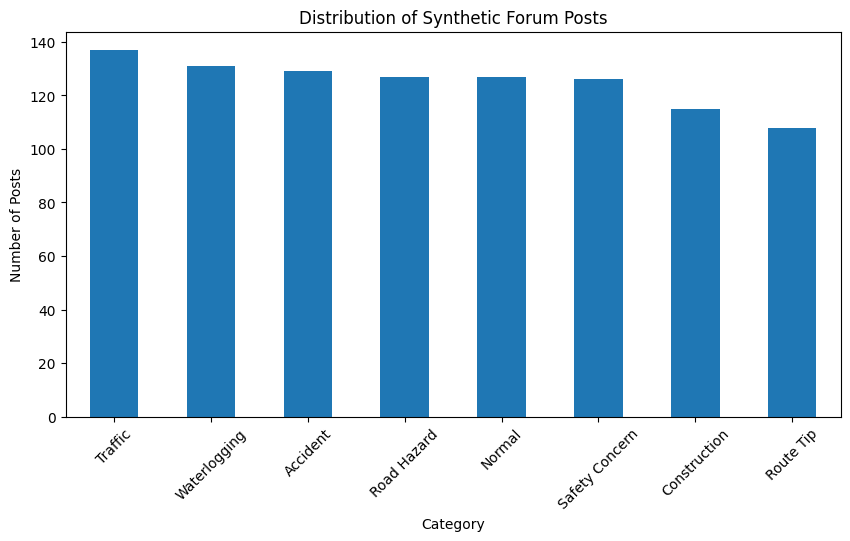

In [ ]:
#visualizing it
import matplotlib.pyplot as plt

forum_posts["category"].value_counts().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of Synthetic Forum Posts")
plt.xlabel("Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.show()

In [ ]:
print(forum_posts.isnull().sum())
print(forum_comments.isnull().sum())

post_id                0
user_id                0
title                  0
text                   0
category               0
subcategory            0
severity               0
location_name          0
latitude               0
longitude              0
created_at             0
observed_at            0
expires_at             0
sentiment              0
upvotes                0
comment_count          0
status                 0
source_type            0
verification_status    0
is_synthetic           0
template_id            0
dtype: int64
comment_id      0
post_id         0
user_id         0
comment_text    0
created_at      0
sentiment       0
source_type     0
is_synthetic    0
dtype: int64


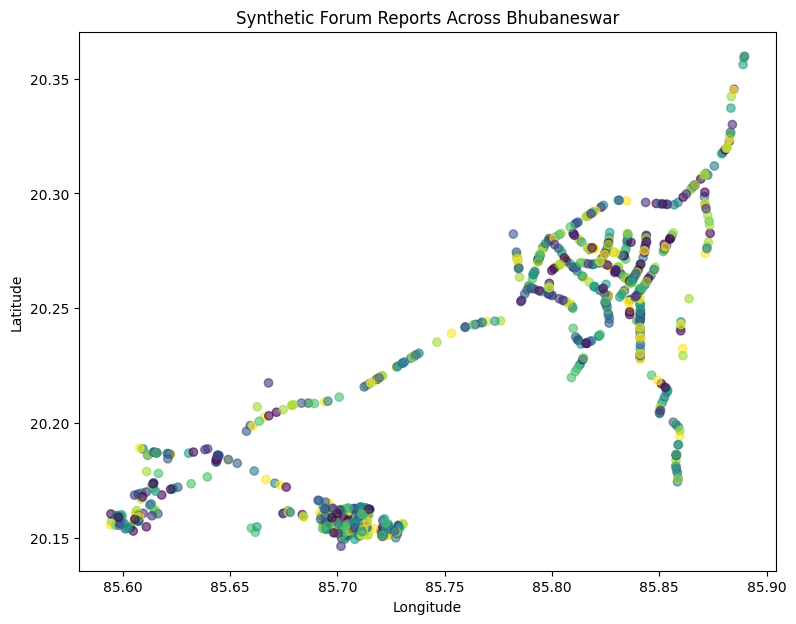

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.scatter(
    forum_posts["longitude"],
    forum_posts["latitude"],
    c=forum_posts["category"].astype("category").cat.codes,
    alpha=0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Synthetic Forum Reports Across Bhubaneswar")
plt.show()

In [ ]:
print(
    forum_comments["post_id"].isin(
        forum_posts["post_id"]
    ).all()
)

True
